<a href="https://colab.research.google.com/github/novaladriann/pm-turi4-clustering-noval/blob/main/PM_TuRi4_Clustering(K_Means)_Noval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def buat_kelompok(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia': rng.integers(usia[0], usia[1] + 1, n),
        'pendapatan': rng.normal(pendapatan[0], pendapatan[1], n).round(-4),
        'skor_belanja': rng.integers(skor[0], skor[1] + 1, n),
    })

df = pd.concat([
    buat_kelompok(50, (18, 30), (5_000_000, 1_200_000), (65, 95)),
    buat_kelompok(50, (35, 50), (14_000_000, 2_500_000), (15, 45)),
    buat_kelompok(50, (50, 65), (8_500_000, 1_500_000), (35, 65)),
], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
df['pendapatan'] = df['pendapatan'].clip(lower=2_000_000)

print('Ukuran data:', df.shape)
df.describe().round(1)

Ukuran data: (150, 3)


,usia,pendapatan,skor_belanja
count,150.0,150.0,150.0
mean,41.3,9039933.3,53.5
std,14.0,4014779.8,22.5
min,18.0,2980000.0,15.0
25%,28.0,5710000.0,38.0
50%,42.0,8200000.0,52.0
75%,52.0,11897500.0,74.0
max,65.0,21280000.0,95.0


Data berisi 150 baris dan 3 kolom numerik tanpa label. Rentang fitur sangat berbeda: `usia` 18–65, `skor_belanja` 15–95, sedangkan `pendapatan` sekitar 3 juta sampai 21 juta. Selisih skala inilah yang membuat scaling wajib dilakukan pada Langkah 1.

### Langkah 1 — Menyiapkan data & scaling (wajib)

In [8]:
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

print('Rata-rata tiap fitur:', X_scaled.mean(axis=0).round(2))
print('Std tiap fitur      :', X_scaled.std(axis=0).round(2))

Rata-rata tiap fitur: [ 0. -0. -0.]
Std tiap fitur      : [1. 1. 1.]


Setelah `StandardScaler`, setiap fitur memiliki rata-rata 0 dan standar deviasi 1. Dengan begitu `pendapatan` (jutaan) tidak lagi mendominasi perhitungan jarak, dan ketiga fitur berkontribusi setara dalam pembentukan cluster.

### Langkah 2 — Metode Elbow menentukan K

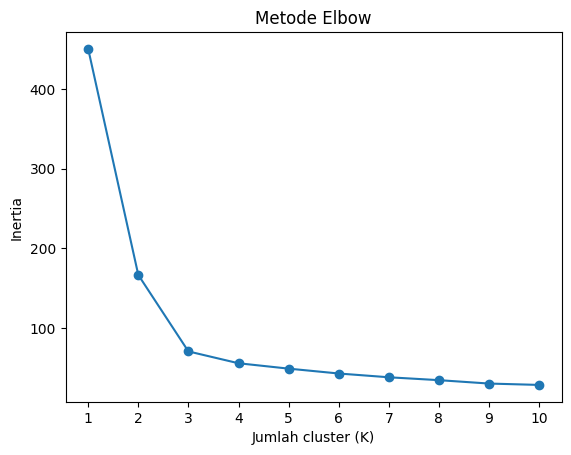

In [9]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia'); plt.title('Metode Elbow')
plt.xticks(range(1, 11)); plt.show()

Inertia selalu turun saat K bertambah. Penurunannya sangat tajam dari K=1 (±450) ke K=2 (±167) dan K=3 (±71), tetapi setelah K=3 hanya turun sedikit (K=4 ±56, K=5 ±49) sehingga kurva melandai. Titik perubahan dari curam ke landai (**siku**) berada di **K = 3**, jadi 3 cluster dipilih sebagai keseimbangan antara kesederhanaan dan kualitas pengelompokan.

### Langkah 3 — Menjalankan K-Means (K=3)

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    51
0    50
2    49
Name: count, dtype: int64


 K-Means membagi 150 pelanggan ke tiga cluster dengan jumlah anggota yang hampir seimbang (sekitar 50 pelanggan per cluster). Hal ini sesuai dengan cara data dibuat, yaitu tiga kelompok pelanggan berukuran sama, sehingga K-Means berhasil menemukan struktur tersebut tanpa pernah melihat label.

### Langkah 4 — Evaluasi silhouette score

In [11]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.5996368871376635


Silhouette score sebesar **0,600** (rentang −1 sampai +1). Nilai ini jauh di atas 0 dan cukup dekat ke +1, artinya sebagian besar titik berada di dalam clusternya dan terpisah baik dari cluster tetangga. Kualitas clustering K=3 tergolong baik.

### Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [12]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        24.5   5053000.0          79.7
1        42.3  13642156.9          29.9
2        57.2   8318163.3          51.5


Profil rata-rata menunjukkan tiga kelompok yang berbeda jelas:
- **Cluster 0:** usia rata-rata ±24,5 tahun, pendapatan ±Rp5,05 juta (paling rendah), skor belanja ±79,7 (paling tinggi).
- **Cluster 1:** usia ±42,3 tahun, pendapatan ±Rp13,6 juta (paling tinggi), skor belanja ±29,9 (paling rendah).
- **Cluster 2:** usia ±57,2 tahun, pendapatan ±Rp8,3 juta (menengah), skor belanja ±51,5 (sedang).

**Penamaan cluster** (berdasarkan profil di atas):

In [13]:
nama_cluster = {0: 'Muda & Boros', 1: 'Mapan & Hemat', 2: 'Senior & Moderat'}
df['segmen'] = df['cluster'].map(nama_cluster)
print(df['segmen'].value_counts())

segmen
Mapan & Hemat       51
Muda & Boros        50
Senior & Moderat    49
Name: count, dtype: int64


| Cluster | Nama | Alasan |
|---|---|---|
| 0 | **Muda & Boros** | Usia paling muda, pendapatan paling rendah, tetapi skor belanja tertinggi |
| 1 | **Mapan & Hemat** | Pendapatan paling tinggi, tetapi skor belanja paling rendah |
| 2 | **Senior & Moderat** | Usia paling tua, pendapatan dan skor belanja di level menengah |

## D. Latihan Mandiri
### Latihan 1 — K-Means K=5, bandingkan silhouette dengan K=3

In [14]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_k5 = km5.fit_predict(X_scaled)
print('Silhouette K=3 :', round(silhouette_score(X_scaled, df['cluster']), 3))
print('Silhouette K=5 :', round(silhouette_score(X_scaled, label_k5), 3))

Silhouette K=3 : 0.6
Silhouette K=5 : 0.514


 Silhouette K=3 (0,600) lebih tinggi daripada K=5 (0,514). Data ini memang tersusun dari 3 kelompok alami; dengan K=5, kelompok yang utuh dipecah menjadi bagian-bagian yang saling berdekatan, sehingga banyak titik berada di perbatasan antar-cluster dan silhouette turun. Ini sejalan dengan hasil Elbow yang menunjuk K=3.

### Latihan 2 — K-Means tanpa scaling (K=3), bandingkan silhouette-nya

In [15]:
X_mentah = df[['usia', 'pendapatan', 'skor_belanja']]   # tanpa scaling
label_mentah = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_mentah)
print('Silhouette dengan scaling :', round(silhouette_score(X_scaled, df['cluster']), 3))
print('Silhouette tanpa scaling  :', round(silhouette_score(X_mentah, label_mentah), 3))

Silhouette dengan scaling : 0.6
Silhouette tanpa scaling  : 0.564


Silhouette tanpa scaling (0,564) lebih rendah daripada dengan scaling (0,600). Tanpa scaling, `pendapatan` yang bernilai jutaan mendominasi perhitungan jarak, sedangkan `usia` dan `skor_belanja` (puluhan) nyaris tidak berpengaruh, sehingga cluster hampir hanya ditentukan oleh pendapatan.

**Kesimpulan:** scaling wajib pada K-Means agar setiap fitur berkontribusi adil. Melewatkannya menurunkan kualitas dan membuat cluster bias terhadap fitur berskala besar.

### Latihan 3 — Scatter plot cluster: usia (x) vs skor_belanja (y)

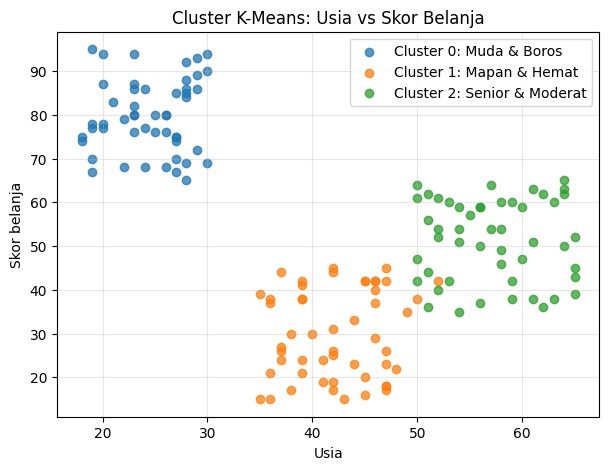

In [16]:
plt.figure(figsize=(7, 5))
for c, sub in df.groupby('cluster'):
    plt.scatter(sub['usia'], sub['skor_belanja'], label=f'Cluster {c}: {nama_cluster[c]}', alpha=0.75)
plt.xlabel('Usia'); plt.ylabel('Skor belanja')
plt.title('Cluster K-Means: Usia vs Skor Belanja')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Pelanggan muda (cluster 0) berkumpul di skor belanja tinggi, kelompok usia menengah (cluster 1) di skor belanja rendah, dan kelompok senior (cluster 2) di skor belanja sedang. Ketiga cluster terpisah jelas pada dua sumbu ini, yang menguatkan bahwa pengelompokan K-Means bermakna.

## E. Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**
K-Means meletakkan K centroid awal secara acak, memasukkan tiap titik ke centroid terdekat (assignment), lalu menghitung ulang centroid sebagai rata-rata anggotanya (update). Dua langkah ini diulang sampai centroid tidak berpindah (konvergen). Kelompok terbentuk murni dari kemiripan jarak antar-titik, tanpa jawaban benar.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**
Karena data tersusun dari 3 kelompok alami. Sampai K=3, tiap penambahan cluster memisahkan kelompok sebenarnya sehingga inertia turun tajam. Setelah K=3, cluster tambahan hanya memecah kelompok yang sudah rapat, penurunan inertia kecil, dan kurva melandai membentuk siku.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**
K-Means berbasis jarak. Tanpa scaling, fitur berskala besar (pendapatan) mendominasi jarak sehingga fitur lain hampir tak berpengaruh. Dampaknya silhouette turun (0,600 menjadi 0,564) dan cluster menjadi bias terhadap satu fitur.
